# Step 2: Delamination Time Analysis

Second step of the cell delamination video analysis pipeline. Takes Excel outputs from Step 1 and:
1. Fits piecewise linear models (Savitzky-Golay smoothed) to each pixel's brightness over time
2. Identifies delamination start times per pixel
3. Outputs heatmaps, histograms, and summary statistics (median, mean, mode, std)

## Requirements
```
pip install numpy pandas matplotlib opencv-python seaborn pwlf tifffile tqdm openpyxl
```
Or use the provided `Cell2spec_anaconda_environment.yaml`:
```
conda env create -f Cell2spec_anaconda_environment.yaml
```

## How to use
1. Run Step 1 first to generate cropped Excel files
2. Update the **Configuration** cell with your file names and output directory
3. Set `exposure`, `height`, and `width` in the Example Use cell to match your experiment
4. Run all cells sequentially

> **Note:** Documentation was generated with AI assistance.


## For Initial Install

In [ ]:
pip install numpy pandas matplotlib opencv-python seaborn pwlf tifffile tqdm

## Import Libraries

In [ ]:
# ============================================================
# CONFIGURATION — update these before running
# ============================================================

# List of filenames to process (without extension) — must match Step 1 output names
FILE_NAMES = ['your_file_1', 'your_file_2']  # <-- update this

# Folder where Step 1 Excel outputs are saved, and where Step 2 results will be saved
OUTPUT_DIR = "path/to/your/output"  # <-- update this (same as Step 1 OUTPUT_DIR)

# File extension for Step 1 output files
DATA_EXTENSION = "xlsx"

# Subfolder name containing Step 1 cropped Excel files
CROPPED_EXCEL_FOLDER = "Cropped_Excel"  # update if different


In [1]:
import numpy as np
import pandas as pd
import os                                           #operating system: to import and save files directly to downloads folder
import tifffile                                     #to import tiff images
import matplotlib.pyplot as plt                     #to plot and view results
import cv2 as cv                                    #for computer vision (to identify cells)
import seaborn as sb                                #for plotting 
import pwlf                                         #for curve fitting
import concurrent.futures                           #for multi-threading
from tqdm import tqdm                               #for user interface

# get directory (this will be the operating system (OS) direction for the code to find your "This PC" folder)
home_dir = os.path.expanduser("~")

data_extension = "xlsx"                       
img_extension = "jpg"

## Define Functions

In [2]:
class FolderManager():
    # Constructor
    # home_path: path to the home directory (e.g. /home/user)
    # workplace_path: path to the workplace directory (e.g. ~/Downloads/workplace)
    def  __init__(self, home_path, workplace_path):
        self.home_path = home_path
        self.workplace_path = workplace_path

    # Create a folder in the workplace directory with the given name
    # Parameters:
    # folder_name: name of the folder to be created
    # Returns: the path of the created folder
    # if a folder with the same name already exists, it prints a message and does not create a new folder
    def create_folder(self, folder_name):
        path = os.path.join(self.home_path, self.workplace_path, folder_name)
        absolute_path = os.path.abspath(path)

        if os.path.exists(path):
            print(f"Folder with name {folder_name} already exists at {absolute_path}")
        
        else:
            os.makedirs(path)
            print(f"Folder with name {folder_name} created at {absolute_path}")

        return path

In [4]:
# finds the video within the computer files, uploads it, and converts it to a dataframe
# also multiplies the timepoints by the exposure (as collumns will be saved as 1 fps otherwise)
# video_path -> you get this from running define_paths, just plug it back in
#
# df -> the video dataframe. will be saved 2D with pixel number in the rows (confirm this?) and time points in the columns

def upload_video(video_path):
    df = pd.read_excel(video_path)

    df = df.drop(df.columns[0], axis=1)
    
    #multiply by exposure
    df.columns = df.columns * exposure
    
    print("Uploaded:", video_path)

    return df

In [5]:
# will automatically create a folder in which to save data (called within define_paths)
# you should not need to touch this
# folder_name -> what you want to call the folder (folder names already selected within define_paths)
# directory -> what folder path you need to follow to get there (from files)
# home_dir -> general location on the computer (how to get to the operating system I think?)
#
# path -> the path to the folder you just created where stuff wil be saved

def make_folder(folder_name, directory, home_dir):
    
    # Combine the parent directory and new folder name to get the full path
    path = os.path.join(home_dir, directory, folder_name)
    
    # Print the absolute path
    absolute_path = os.path.abspath(path)

    # Check if the directory already exists
    if not os.path.exists(path):
        # Create the directory if it does not exist
        os.makedirs(path)
        print(f"Folder '{folder_name}' created at '{absolute_path}'")
    
    else:
        # Check if the path is a directory
        if os.path.isdir(path):
            print(f"Folder '{folder_name}' already exists at '{absolute_path}' \n")
            
        else:
            print(f"A file with the name '{folder_name}' exists at '{absolute_path}' \n")
    
    return path

In [6]:
# Multi-threading
# takes the dataframe of pixel number vs brightness, and graphs each pixel brightness vs time.
# fits a line of degree 1, 3, or 5 to the curve (see fit_model for how) and selects the initial
# and final breakpoints of the line.
# 
# degree -> a list containing the degree of each pixel
# start_times -> a list containing the first breakpoint (or start of delamination) for each pixel
#                could possibly be used to identify at which points the lysis solution begins to act 
#                on the cells after confinement begins (where brightness begins to drop)
#                If the line is of degree 1, returns NaN.
# end_times -> a list containing the last breakpoint of the model fit. This will be the delamination
#              time. If the line is of degree 1, returns NaN.

max_workers = os.cpu_count() - 2         #Leave two cores free for the operating system and processes

def process_row(index, row, df):
    line_degree, breakpoints = fit_model(row, df)
    
    if line_degree == 1:
        start_time = np.nan
        end_time = np.nan
    elif line_degree == 3:
        start_time = breakpoints[1]
        end_time = breakpoints[2]
    elif line_degree == 5:
        start_time = breakpoints[1]
        end_time = breakpoints[4]

    return index, start_time, end_time, line_degree

def identify_delam_times_order135(df):
    start_times = [None] * len(df)
    end_times = [None] * len(df)
    degrees = [None] * len(df)

    with concurrent.futures.ThreadPoolExecutor() as executor:
        futures = {executor.submit(process_row, index, row, df): index for index, row in df.iterrows()}
        
        # Use tqdm to display progress
        for future in tqdm(concurrent.futures.as_completed(futures), total=len(futures), desc="Processing pixels"):
            index, start_time, end_time, line_degree = future.result()
            start_times[index] = start_time
            end_times[index] = end_time
            degrees[index] = line_degree
    
    return start_times, end_times, degrees

In [7]:
# actually does the fitting of degree to the curve
# row -> the row of data (will be isolated in identify_delam_times_order135 and passed automatically)
# df -> the dataframe (this is here because I can't be bothered to find a way to pass column (exposure)
#       information through to the next function without losing exposure)
# print_seg -> if this is set to true, it will show the a scatterplot of data with the fitted line 
#              over top (will automatically be set as false). Can help visualize data if something
#              goes wrong.
# threshold -> an arbitrary threshold I set (RSS is smaller with overfitting, by selecting 50 as 
#              a threshold, we can get a fitted line, without overfitting. May need to be tweaked,
#              use the print_seg=True to visualize a better value to use.
#
# best_fit_rss -> returns whether the algorithm selected 1, 3, or 5 segments
# results[best_fit_rss]['breakpoints'] -> all results are saved to a dataframe,
#                                         this selects the best one to return.

def fit_model(row, df, print_seg=False):
    # Find the first fit with RSS under 50
    threshold = 50
    
    results = {}
    
    for num_segments in [1, 3, 5]:
        model, breakpoints, x, y, y_hat, rss = fit_pwlf(row, df, num_segments)
        
        results[num_segments] = {
            'model': model,
            'breakpoints': breakpoints,
            'y_hat': y_hat,
            'rss': rss
        }
    
    best_fit_rss = None
    for num_segments in [1, 3, 5]:
        if results[num_segments]['rss'] < threshold:
            best_fit_rss = num_segments
            break

    # If no RSS is under 50, use the original criteria
    if best_fit_rss is None:
        best_fit_rss = min(results, key=lambda k: results[k]['rss'])
    
    if print_seg == True:
        print(f'Number of Segments Selected for Best Fit: {best_fit_rss}')

        # Plot the results
        plt.scatter(x, y, label='Data', s=0.7)
        for num_segments, result in results.items():
           plt.plot(x, result['y_hat'], label=f'{num_segments} segments fit')
        plt.legend()
        plt.ylim(bottom=0, top=70)
        plt.show()
    
    #print("results:", results[best_fit_rss]['breakpoints'])
        
    return best_fit_rss, results[best_fit_rss]['breakpoints']

In [8]:
# Function to fit pwlf model and calculate Root Sum of Squares (RSS)
# to be honest, I'm not 100% sure of how this one works, but going to see the pwlf documentation might help if there are issues
# (there should not be issues, it has worked consistently so far).

def fit_pwlf(y, df, num_segments):
    
    #indices cause a floating point error that I don't have the time to figure out, so I am round them and make into an array
    indices = np.round(np.array(df.columns, dtype=float), 1)
    
    x = indices
    
    model = pwlf.PiecewiseLinFit(x, y)
    breakpoints = model.fit(num_segments)
    y_hat = model.predict(x)
    
    # Calculate RSS
    rss = np.sum((y - y_hat) ** 2)
    
    #print("Num_segments:", num_segments)
    #print("RSS:", rss)
    
    return model, breakpoints, x, y, y_hat, rss

In [9]:
# Graph a heatmap with delamination times
# filename -> the file name
# decell_time_df -> this is end_times returned by identify_delam_times_order135
# vmax=100 -> the maximum value on the heatmap scale (this can be used for consistency between 
#             experiments). Will automatically be set to 100, unless otherwise stated
# save=False -> heatmaps will not automatically save (as the file name will be the same, running
#               this code will delete and replace any file with the same name and path that is already saved.
#               Save will be automatically set to False to avoid deleting results. Set to True to save

def graph_heatmap(filename, decell_time_df, vmax=100, save=False):
    #Show delamination as a function of time on heatmap
    
    reshaped = decell_time_df.values.reshape(height, width)

    sb.heatmap(
        reshaped, 
        cmap="viridis",                     #change color scheme
        cbar=True,                          #color bar included
        mask = (reshaped == 0),             #remove values == 0 from graph (will show up gray)
        square=True,                        #pixel length and width are equal
        xticklabels=False,                  #do not label x-axis
        yticklabels=False,                  #do not label y-axis
        vmin=0,
        vmax=vmax
    )

    #save image BEFORE plotting (otherwise there are errors in saving)
    if save == True:
        full_path_heatmap = os.path.join(heatmaps_path, f"{filename}.{img_extension}")
        plt.savefig(full_path_heatmap)
        
        #find how to save data as excel     

    plt.show()
    
    if save == True:
        full_path_heatmap_data = os.path.join(heatmaps_excel_path, f"{filename}.{data_extension}")
        
        reshaped_df = pd.DataFrame(reshaped)
        
        reshaped_df.to_excel(full_path_heatmap_data, index=False)

In [10]:
# graphs the histogram
# filename -> the file name
# decell_time_df -> this is end_times returned by identify_delam_times_order135
# save=False -> histograms will not automatically save (as the file name will be the same, running
#               this code will delete and replace any file with the same name and path that is already saved.
#               Save will be automatically set to False to avoid deleting results. Set to True to save
#
# unique_times -> the unique times at which delamination occurs (numpy array)
# counts -> the delamination counts (in order) associated with the unique_times

def graph_histogram(filename, decell_time_df, save=False):
    # This was important at some point but I forget why
    unique_times1, counts1 = np.unique(decell_time_df, return_counts=True, equal_nan=True) 

    # will return all NaN (zero) values summed as last entry (unique_times and counts will be 1 too long)
    unique_times = unique_times1[:-1] #used 1 to avoid errors while rerunning
    counts = counts1[:-1]

    plt.figure(figsize=(10, 6))  # Adjust figure size
    plt.bar(unique_times, counts) 
    plt.xlabel('Time (s)')
    plt.ylabel('Cell Delamination')
    plt.title('Cell Delamination over Time')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.xticks(rotation=45)  # Rotate x-axis labels for better readability
    plt.tight_layout()  # Adjust spacing for labels and titles
    plt.xlim(left=0)     #x-axis will start at 0

    #save file before plotting
    if save==True:
        plt.savefig(delam_time_hist_path)
        
        delam_time_hist_path_full = os.path.join(delam_time_hist_path, f"{filename}.{img_extension}")
        plt.savefig(delam_time_hist_path_full)
        
        delam_time_excel_path
        
        
    plt.show()
    
    return unique_times, counts

In [11]:
# Once you have run the fitting function, this will get you the delam time median, mean, mode, standard deviation,
# an excel sheet with time vs cells delaminated (at that time), and will get the total delamination events
# (each pixel delamination is counted as 1 currently, but using the list of line degrees, 3 degree can count
# as one delamination event and 5 degree can count as 2 delamination events to get a more accurate result)
#
# decell_time_df -> this is the end_times returned by identify_delam_times_order135
# unique_times -> returned by graph_histogram
# counts -> returned by graph_histogram

def info(decell_time_df, unique_times, counts):
    # Calculate median, mode and mean of above graph
    
    no_zero = decell_time_df[decell_time_df != 0]

    median = no_zero.median()
    mean = no_zero.mean()
    mode = no_zero.mode()
    sdev = no_zero.std()

    print("Exposure (ms):", exposure*1000)
    print('Median:', median)
    print('Mean:', mean)
    print('Mode:', mode)
    print('Standard Deviation', sdev)
    
    time_vs_count = {'Time (s)': unique_times, 'Delamination Count': counts}
    time_vs_count_df = pd.DataFrame(time_vs_count)
    
    total_delam_events = time_vs_count_df['Delamination Count'].sum()
    print('Delamination Events (Pixels Delaminated):', total_delam_events)
    
    full_delam_time_excel_path = os.path.join(delam_time_excel_path, f"{file}.{data_extension}")
    time_vs_count_df.to_excel(full_delam_time_excel_path, index=False)

# Example Use:

In [12]:
#input important info
exposure = 0.6     # in seconds
height = 22        # enter height of cropped video (this will be h/cell_size - from previous code)
width = 24         # enter width of cropped video (this will be w/cell_size - from previous code)

path_to_workplace = OUTPUT_DIR  # set in config cell above
                                                              # whatever folder pathway is listed here)
cropped_excel_folder = "Cropped_Excel"                        # This is the folder the cropped excel video from part 1 is saved in. 
                                                              # Should be within Downloads//CFPAC_NAO_Test

# List all files you want processed here
file_names = ['20240627_col_(1)_delamtime_vs_count', '20240627_col_(2)_delamtime_vs_count']

video: 20240627_col_(1)_delamtime_vs_count
uploading file...
Creating Directories:
Folder with name Heatmaps already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Heatmaps
Folder with name Heatmaps_Excel already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Heatmaps_Excel
Folder with name Delam_Time_Histogram already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Delam_Time_Histogram
Folder with name Delam_Time_Excel already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Delam_Time_Excel
Uploaded: C:\Users\Quant-Tech-BM\Downloads//CFPAC_NAO//Test\Cropped_Excel\20240627_col_(1)_delamtime_vs_count.xlsx


identifying delam time...


Processing pixels: 100%|██████████| 528/528 [13:15<00:00,  1.51s/it]


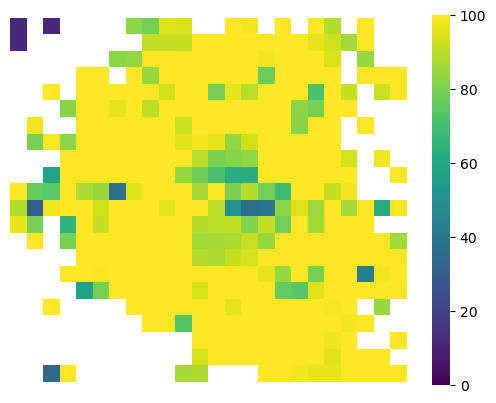

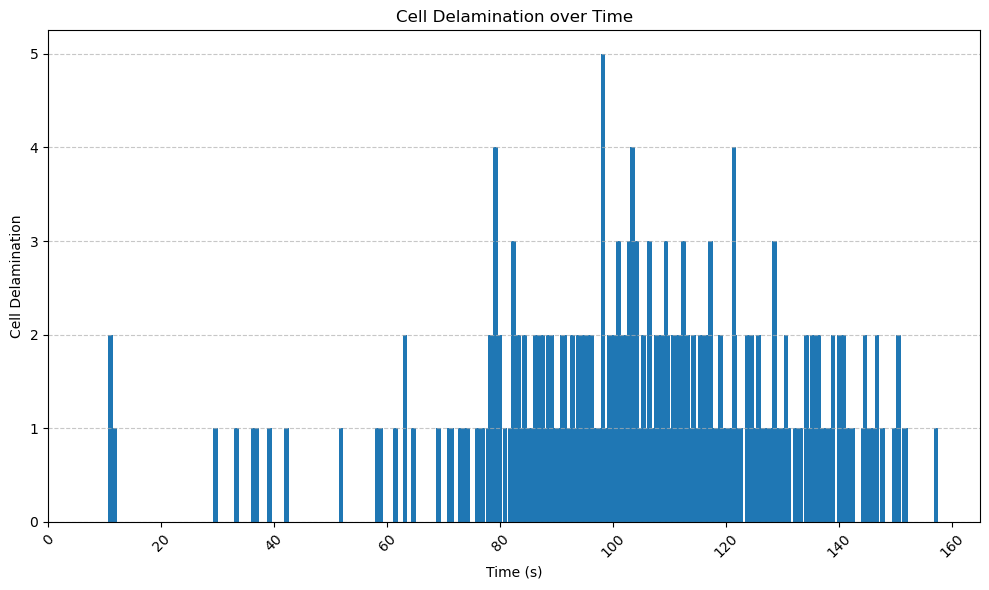

Exposure (ms): 600.0
Median: ColumnName    106.5
dtype: float64
Mean: ColumnName    106.518766
dtype: float64
Mode:    ColumnName
0        98.2
Standard Deviation ColumnName    23.263179
dtype: float64
Delamination Events (Pixels Delaminated): 389


video: 20240627_col_(2)_delamtime_vs_count
uploading file...
Creating Directories:
Folder with name Heatmaps already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Heatmaps
Folder with name Heatmaps_Excel already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Heatmaps_Excel
Folder with name Delam_Time_Histogram already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Delam_Time_Histogram
Folder with name Delam_Time_Excel already exists at C:\Users\Quant-Tech-BM\Downloads\CFPAC_NAO\Test\Delam_Time_Excel
Uploaded: C:\Users\Quant-Tech-BM\Downloads//CFPAC_NAO//Test\Cropped_Excel\20240627_col_(2)_delamtime_vs_count.xlsx


identifying delam time...


Processing pixels: 100%|██████████| 528/528 [18:18<00:00,  2.08s/it]


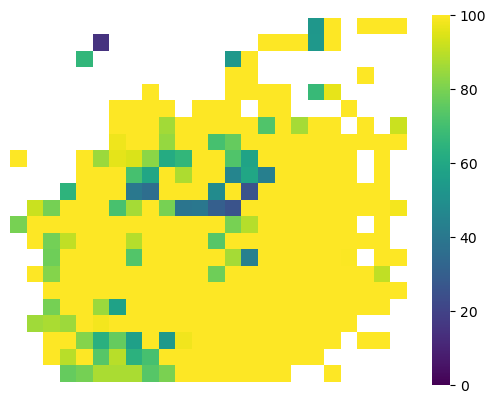

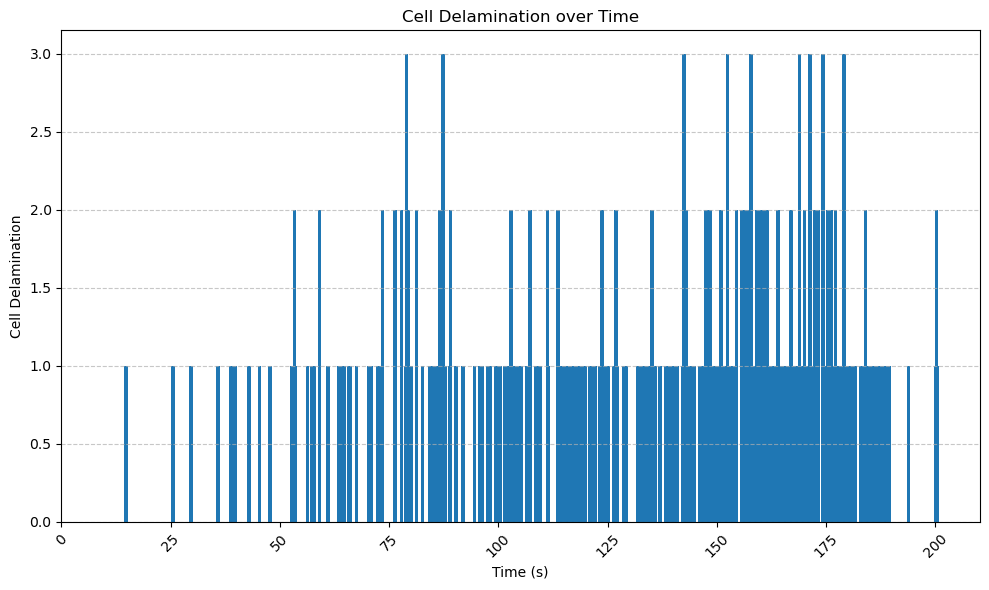

Exposure (ms): 600.0
Median: ColumnName    143.2
dtype: float64
Mean: ColumnName    132.374286
dtype: float64
Mode:    ColumnName
0        79.0
1        87.3
2       142.5
3       152.4
4       157.8
5       168.9
6       171.3
7       174.3
8       179.1
Standard Deviation ColumnName    41.186022
dtype: float64
Delamination Events (Pixels Delaminated): 350


done


In [13]:
for file in file_names:
    print("video:", file)
    video_path = os.path.join(home_dir, path_to_workplace, cropped_excel_folder, f"{file}.{data_extension}")

    print("uploading file...")
    folder_manager = FolderManager(home_dir, path_to_workplace)
    
    print("Creating Directories:")
    heatmaps_path = folder_manager.create_folder("Heatmaps")
    heatmaps_excel_path = folder_manager.create_folder("Heatmaps_Excel")
    delam_time_hist_path = folder_manager.create_folder("Delam_Time_Histogram")
    delam_time_excel_path = folder_manager.create_folder("Delam_Time_Excel")
    
    df = upload_video(video_path)

    print("\n")

    print("identifying delam time...")

    start_times, end_times, line_degree =  identify_delam_times_order135(df)

    end_times_df = pd.DataFrame(end_times, columns=['ColumnName'])

    graph_heatmap(file, end_times_df, 100, True)

    #Remove floating point error (round to one decimal place)
    end_times_df_rounded = end_times_df.round(1)

    unique_times, counts = graph_histogram(file, end_times_df_rounded, True)

    info(end_times_df_rounded, unique_times, counts)

    print("\n")
    
print("done")